**Activity 5 — Data Cleaning & Outlier Detection with Visualization**

Use the exact dataset supplied in the activity.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

employee_data = pd.DataFrame({
    "Name": ["Ahsan", "Hira", "Bilal", "Zara", "Salman", "Mahnoor"],
    "Age": [25, 27, 35, 29, None, 40],
    "Salary": [50000, None, 75000, 2000000, 60000, 90000],
    "Department": ["IT", "Finance", "IT", "HR", "Finance", "IT"]
})

print(employee_data)

      Name   Age     Salary Department
0    Ahsan  25.0    50000.0         IT
1     Hira  27.0        NaN    Finance
2    Bilal  35.0    75000.0         IT
3     Zara  29.0  2000000.0         HR
4   Salman   NaN    60000.0    Finance
5  Mahnoor  40.0    90000.0         IT


In [2]:
employee_data["Age"] = employee_data["Age"].fillna(employee_data["Age"].median())
employee_data["Salary"] = employee_data["Salary"].fillna(employee_data["Salary"].median())

print(employee_data)

      Name   Age     Salary Department
0    Ahsan  25.0    50000.0         IT
1     Hira  27.0    75000.0    Finance
2    Bilal  35.0    75000.0         IT
3     Zara  29.0  2000000.0         HR
4   Salman  29.0    60000.0    Finance
5  Mahnoor  40.0    90000.0         IT


In [3]:
employee_encoded = pd.get_dummies(
    employee_data, columns=["Department"], dtype=int
)
print(employee_encoded)

      Name   Age     Salary  Department_Finance  Department_HR  Department_IT
0    Ahsan  25.0    50000.0                   0              0              1
1     Hira  27.0    75000.0                   1              0              0
2    Bilal  35.0    75000.0                   0              0              1
3     Zara  29.0  2000000.0                   0              1              0
4   Salman  29.0    60000.0                   1              0              0
5  Mahnoor  40.0    90000.0                   0              0              1


C:\Users\DELL\AppData\Local\Temp\ipykernel_4732\1134125207.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(employee_data["Salary"], vert=False)


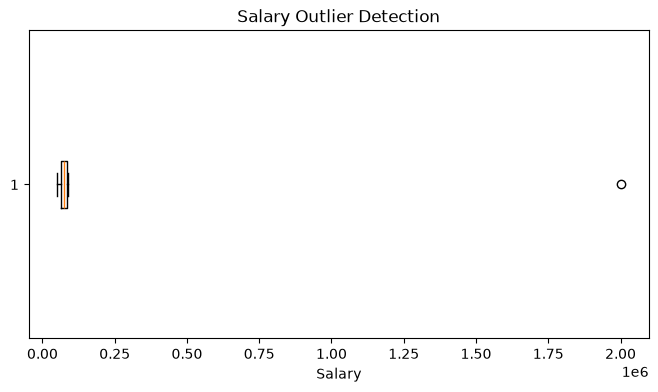

IQR bounds: 30000.0 to 120000.0
Outliers:
   Name     Salary
3  Zara  2000000.0


In [4]:
q1 = employee_data["Salary"].quantile(0.25)
q3 = employee_data["Salary"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

salary_outliers = employee_data[
    (employee_data["Salary"] < lower) |
    (employee_data["Salary"] > upper)
]

plt.figure(figsize=(8, 4))
plt.boxplot(employee_data["Salary"], vert=False)
plt.xlabel("Salary")
plt.title("Salary Outlier Detection")
plt.show()

print("IQR bounds:", lower, "to", upper)
print("Outliers:")
print(salary_outliers[["Name", "Salary"]])

In [5]:
zara_salary = employee_data.loc[
    employee_data["Name"].eq("Zara"), "Salary"
].iloc[0]

print("Zara's salary:", zara_salary)
print("Zara is an IQR outlier:", zara_salary > upper)

Zara's salary: 2000000.0
Zara is an IQR outlier: True
